In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns

In [ ]:
pdata = pd.read_csv('/content/fake_or_real_news.csv')
pdata.shape

/tmp/ipykernel_3286/1326571133.py:1: DtypeWarning: Columns (22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138) have mixed types. Specify dtype option on import or set low_memory=False.
  pdata = pd.read_csv('/content/fake_or_real_news.csv')


(7795, 139)

In [ ]:
pdata.head()

,text,label,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 129,Unnamed: 130,Unnamed: 131,Unnamed: 132,Unnamed: 133,Unnamed: 134,Unnamed: 135,Unnamed: 136,Unnamed: 137,Unnamed: 138
0,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,U.S. Secretary of State John F. Kerry said Mon...,REAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,It's primary day in New York and front-runners...,REAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(df.columns.tolist()[:10])
print(df.iloc[:3, :4])

with open('/content/fake_or_real_news.csv', encoding='utf-8', errors='ignore') as f:
    print(f.read(600))

['text', 'label', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9']
                                                text label Unnamed: 2  \
0  Daniel Greenfield, a Shillman Journalism Fello...  FAKE        NaN   
1  Google Pinterest Digg Linkedin Reddit Stumbleu...  FAKE        NaN   
2  U.S. Secretary of State John F. Kerry said Mon...  REAL        NaN   

  Unnamed: 3  
0        NaN  
1        NaN  
2        NaN  
text,label,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"Daniel Greenfield, a Shillman Journalism Fellow at the Freedom Center, is a New York writer focusing on radical Islam. 
In the final stretch of the election, Hillary Rodham Clinton has gone to war with the FBI. 
The word “unprecedented” has been thrown around so often this election that it ought to be retired. But it’s still unprecedented for the nominee of a major 

In [ ]:
df = pd.read_csv('/content/fake_or_real_news.csv', usecols=['text', 'label'])
print(df.shape)
print(df['label'].value_counts())
print(df.isna().sum())
print(df.duplicated().sum(), "duplicate rows")

#preprocessing
df = df.dropna(subset=['text', 'label']).drop_duplicates().reset_index(drop=True)
df['label_num'] = df['label'].map({'FAKE': 0, 'REAL': 1})
print(df.shape)
print(df['label_num'].value_counts())

(7795, 2)
label
REAL                                                                            3161
FAKE                                                                            3154
 or naturalization or by jus sanguinis – inherited through ancestors/parents       3
 for example                                                                       2
 etc.                                                                              2
                                                                                ... 
 the Jewish settlers had built their houses higher up the mountain. Thus           1
 Tel Aviv–Jaffa                                                                    1
 the Haganah attacked the village of Khisas at night                               1
 and then depart. [61]                                                             1
 are remarkably like those of Nazi Germany.” [81] An elderly man and a girl        1
Name: count, Length: 437, dtype: int64
text      

In [ ]:
print(df['label'].value_counts(dropna=False))
print(df['label'].unique()[:20])

label
FAKE                                                                                                                                               3061
REAL                                                                                                                                               2979
 for example                                                                                                                                          2
 etc.                                                                                                                                                 2
 we’ve also been blessed because of a promise He made to Abraham (“those who bless you                                                                1
                                                                                                                                                   ... 
 Tel Aviv–Jaffa                                                                   

In [ ]:
df['label'] = df['label'].astype(str).str.strip().str.upper()
df = df[df['label'].isin(['FAKE', 'REAL'])].reset_index(drop=True)
df['label_num'] = df['label'].map({'FAKE': 0, 'REAL': 1})

print(df['label_num'].isna().sum(), "NaN baki")
print(df['label_num'].value_counts())

0 NaN baki
label_num
0    3061
1    2979
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df['text']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

vec = TfidfVectorizer(stop_words='english', max_df=0.7, min_df=2)
X_train_vec = vec.fit_transform(X_train)   # shudhu train e fit
X_test_vec = vec.transform(X_test)

print(X_train_vec.shape, X_test_vec.shape)

(4832, 34907) (1208, 34907)


Accuracy: 0.8940397350993378
              precision    recall  f1-score   support

        FAKE       0.90      0.89      0.89       612
        REAL       0.89      0.90      0.89       596

    accuracy                           0.89      1208
   macro avg       0.89      0.89      0.89      1208
weighted avg       0.89      0.89      0.89      1208

[[543  69]
 [ 59 537]]


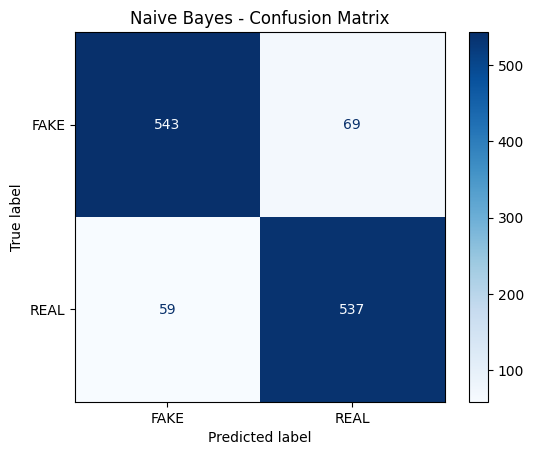

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


nb = MultinomialNB(alpha=0.1)
nb.fit(X_train_vec, y_train)


pred = nb.predict(X_test_vec)
print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, target_names=['FAKE', 'REAL']))

cm = confusion_matrix(y_test, pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=['FAKE', 'REAL']).plot(cmap='Blues')
plt.title('Naive Bayes - Confusion Matrix')
plt.show()

In [ ]:
names = vec.get_feature_names_out()
diff = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
print("Top REAL words:", [names[i] for i in diff.argsort()[-10:][::-1]])
print("Top FAKE words:", [names[i] for i in diff.argsort()[:10]])

Top REAL words: ['fiorina', 'caucuses', 'boehner', 'cruz', 'carson', 'mcconnell', 'nominating', 'presumptive', 'malley', 'contenders']
Top FAKE words: ['assange', 'rt', 'ru', 'sheeple', 'pravda', 'trunews', 'ufo', 'sf', 'wmw_admin', 'halloween']
